# Layer 3: Spatial Expectations & Regional Logistics

### Methodology:
1.  **State-Level Benchmarking:** Calculating average transit times and delay rates for Brazil's 27 states.
2.  **Regional Sensitivity Index:** Measuring the "Review Drop-off" when a delivery is late in a specific state. This quantifies customer patience (e.g., SP vs. AM).
3.  **Logistics "Black Holes":** Identifying the most problematic Seller-State to Customer-State routes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')

print(f"Data loaded: {df.shape}")

Data loaded: (95353, 40)


## 1. State-Level Benchmarking

We calculate the average delivery performance for each state to understand the baseline geographic reality of Brazilian logistics.

C:\Users\Devyansh\AppData\Local\Temp\ipykernel_12736\2607134447.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='state', y='avg_delivery_days', data=state_benchmarks, palette='coolwarm')


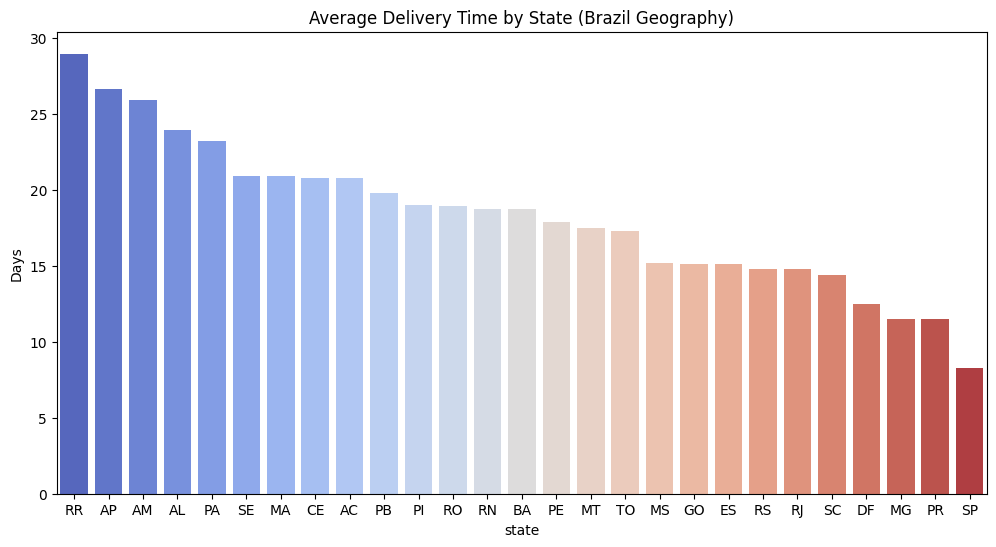

In [2]:
state_benchmarks = df.groupby('customer_state').agg({
    'actual_delivery_days': 'mean',
    'estimated_delivery_days': 'mean',
    'is_late': 'mean',
    'review_score': 'mean'
}).reset_index()

state_benchmarks.columns = ['state', 'avg_delivery_days', 'avg_promise_days', 'late_rate', 'avg_review_score']
state_benchmarks = state_benchmarks.sort_values('avg_delivery_days', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x='state', y='avg_delivery_days', data=state_benchmarks, palette='coolwarm')
plt.title('Average Delivery Time by State (Brazil Geography)')
plt.ylabel('Days')
plt.show()

## 2. Regional Sensitivity Index (The "Review Drop")

A 3-day delay in São Paulo (SP) might trigger a 1-star review, while the same delay in Acre (AC) might be tolerated. 

**Formula:** `Sensitivity = (Avg Score On-Time) - (Avg Score Late)`
A high sensitivity means customers in that state have **zero tolerance** for delays.

C:\Users\Devyansh\AppData\Local\Temp\ipykernel_12736\2714592942.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sensitivity.index, y='review_drop', data=sensitivity, palette='Reds_r')


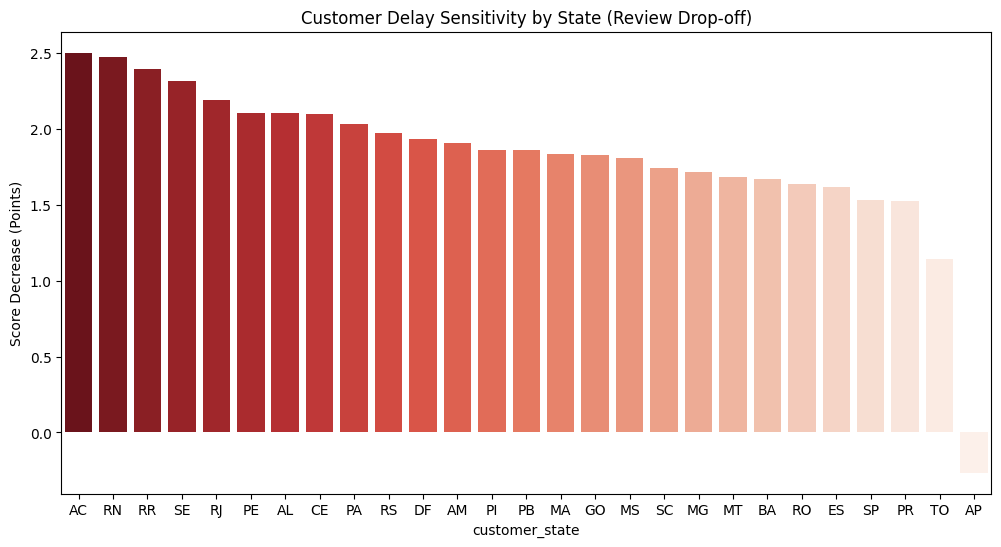

Top 5 Most Sensitive States (Low Tolerance):
is_late                0         1  review_drop
customer_state                                 
AC              4.171053  1.666667     2.504386
RN              4.388889  1.913043     2.475845
RR              4.194444  1.800000     2.394444
SE              4.257951  1.940000     2.317951
RJ              4.243438  2.049096     2.194342


In [3]:
sensitivity = df.groupby(['customer_state', 'is_late'])['review_score'].mean().unstack()
sensitivity['review_drop'] = sensitivity[0] - sensitivity[1]
sensitivity = sensitivity.sort_values('review_drop', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=sensitivity.index, y='review_drop', data=sensitivity, palette='Reds_r')
plt.title('Customer Delay Sensitivity by State (Review Drop-off)')
plt.ylabel('Score Decrease (Points)')
plt.show()

print("Top 5 Most Sensitive States (Low Tolerance):")
print(sensitivity.head(5))

## 3. Logistics "Black Holes" (Route Analysis)

Identifying the Seller-to-Customer routes that consistently fail logistics promises.

Top 5 Logistic Black Holes (Highest Late Rates):
    seller_state customer_state   is_late  review_score  order_id
382           SP             AL  0.241107      3.719368       253
140           MA             SP  0.229508      3.926230       122
282           RJ             CE  0.222222      3.648148        54
390           SP             MA  0.198758      3.731884       483
397           SP             PI  0.177019      3.956522       322


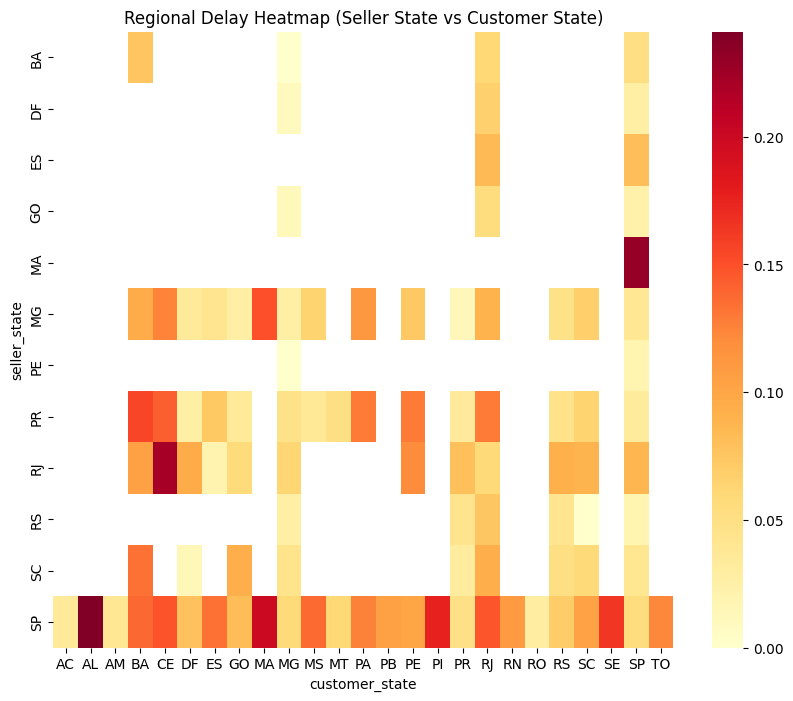

In [4]:
route_analysis = df.groupby(['seller_state', 'customer_state']).agg({
    'is_late': 'mean',
    'review_score': 'mean',
    'order_id': 'count'
}).reset_index()

# Filter for routes with significant volume
black_holes = route_analysis[route_analysis['order_id'] > 50].sort_values('is_late', ascending=False)

print("Top 5 Logistic Black Holes (Highest Late Rates):")
print(black_holes.head(5))

plt.figure(figsize=(10, 8))
pivot_table = black_holes.pivot(index='seller_state', columns='customer_state', values='is_late')
sns.heatmap(pivot_table, cmap='YlOrRd')
plt.title('Regional Delay Heatmap (Seller State vs Customer State)')
plt.show()

## 4. Adjusted Economic Impact (Geographic Weighting)

We update our Economic Framework by assigning a higher "Bad Review Penalty" to states with High Sensitivity.

In [5]:
# Mapping review drop (Sensitivity) back to main dataframe
df = df.merge(sensitivity[['review_drop']], on='customer_state', how='left')

# Formula: Adjusted Cost = Base Cost (R$155) * (Sensitivity / Median Sensitivity)
median_sensitivity = sensitivity['review_drop'].median()
df['geo_adjusted_penalty'] = 155 * (df['review_drop'] / median_sensitivity)

print(f"Average Geo-Adjusted Penalty: R$ {df['geo_adjusted_penalty'].mean():.2f}")
print(f"Maximum Penalty (Ultra-Sensitive State): R$ {df['geo_adjusted_penalty'].max():.2f}")

Average Geo-Adjusted Penalty: R$ 144.10
Maximum Penalty (Ultra-Sensitive State): R$ 208.22
